Inizializzazione: tramite l'azione di una porta di Hadamard sul qubit q_0 e di una porta CNOT controllata da q_0, i due qubit nello stato iniziale |00⟩ vengono portati in uno stato di entanglement, generando lo stato di Bell |ϕ+⟩:


<IPython.core.display.Latex object>


I due qubit vengono ora separati fisicamente: Alice prende il qubit q_1, mentre Bob conserva il qubit q_0.
L'obiettivo di Alice è trasmettere due bit classici a Bob. Per farlo, applica delle porte logiche esclusivamente al suo qubit.

Messaggio scelto: '11'. Alice codifica ora l'informazione sul suo qubit...


<IPython.core.display.Latex object>


Trasmissione: Alice invia il suo qubit (q_1) a Bob attraverso un canale quantistico.
Bob è ora in possesso di entrambi i qubit e applica il protocollo di decodifica.
La decodifica di Bob consiste nell'applicare le operazioni di codifica in ordine inverso (ovvero CNOT seguito da H1) per proiettare i quattro possibili stati di Bell (entangled) di nuovo sulla base computazionale classica (|00⟩, |01⟩, |10⟩, |11⟩
Conclusa la decodifica, i due qubit si trovano nello stato:


<IPython.core.display.Latex object>


Bob procede quindi alla misurazione dei due qubit per estrarre l'informazione classica. Eseguendo 100 simulazioni, si ottiene il seguente risultato:


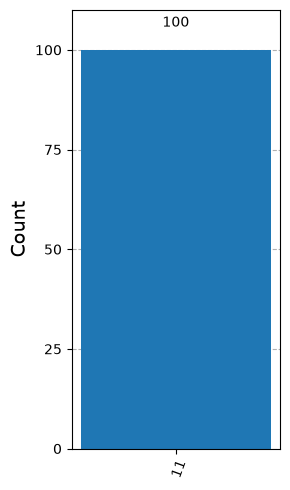


Il circuito quantistico completo generato per questo protocollo è il seguente:


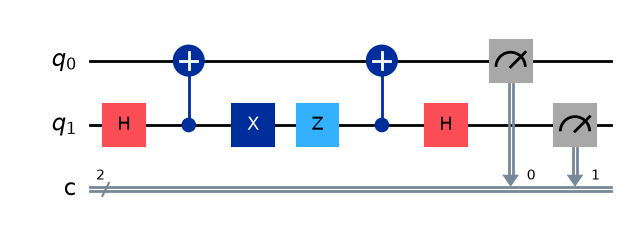

In [5]:

"""
SIMULAZIONE DEL PROTOCOLLO DI CODIFICA SUPERDENSA (SUPERDENSE CODING)

Questo programma dimostra come trasmettere 2 bit classici inviando un solo qubit, 
sfruttando l'entanglement quantistico. 

Il funzionamento si divide in 3 step principali:
1. PREPARAZIONE: Viene generata una coppia di qubit entanglati (Stato di Bell |ϕ+⟩). 
   I qubit vengono divisi tra Alice (q_1) e Bob (q_0).

2. FASE DI CODIFICA: Alice sceglie un messaggio di due bit classici (00, 01, 10 o 11).
   In base al messaggio, applica delle porte quantistiche (X, Z o entrambe) SOLO 
   sul suo qubit (q_1). Questo altera lo stato entangled globale senza che Alice 
   tocchi il qubit di Bob. Alice poi invia il suo qubit a Bob.

3. FASE DI DECODIFICA: Bob, che ora ha entrambi i qubit, applica le operazioni inverse 
   della preparazione (porta CNOT e porta Hadamard su q_1). Questa procedura 
   rompe lo stato di entanglement dei due qubit e trasforma i 4 possibili stati di Bell in 4 stati 
   classici facilmente misurabili (|00⟩, |01⟩, |10⟩, |11⟩). Misurandoli, Bob 
   legge il messaggio di Alice.
"""


from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector, 
    plot_state_qsphere,
    circuit_drawer, 
    plot_histogram
)

# Creazione stato di Bell  |ϕ+⟩
print("Inizializzazione: tramite l'azione di una porta di Hadamard sul qubit q_0 e di una porta CNOT controllata da q_0, i due qubit nello stato iniziale |00⟩ vengono portati in uno stato di entanglement, generando lo stato di Bell |ϕ+⟩:")
qc = QuantumCircuit(2,2)
qc.h(1)
qc.cx(1,0)

# Rappresento con formula latex lo stato di Bell che è stato generato
S= Statevector(qc)
display(S.draw("latex"))

# Separazione dei due qubit
print("\nI due qubit vengono ora separati fisicamente: Alice prende il qubit q_1, mentre Bob conserva il qubit q_0.")
print("L'obiettivo di Alice è trasmettere due bit classici a Bob. Per farlo, applica delle porte logiche esclusivamente al suo qubit.")

# Codifica messaggio
messaggio = ""
while messaggio not in ["01","00","11","10"]:
    messaggio = str(input("\nInserisci i due bit classici che Alice vuole inviare (00, 01, 10 o 11):"))
print(f"\nMessaggio scelto: '{messaggio}'. Alice codifica ora l'informazione sul suo qubit..." )

if messaggio == "01":
    qc.x(1)
    S2= Statevector(qc)
    display(S2.draw("latex"))
if messaggio == "10":
    qc.z(1)
    S2= Statevector(qc)
    display(S2.draw("latex"))
if messaggio == "11":
    qc.x(1)
    qc.z(1)
    S2= Statevector(qc)
    display(S2.draw("latex"))

# Trasmissione del messaggio
print("\nTrasmissione: Alice invia il suo qubit (q_1) a Bob attraverso un canale quantistico.")
print("Bob è ora in possesso di entrambi i qubit e applica il protocollo di decodifica.")

# Decodifica
print("La decodifica di Bob consiste nell'applicare le operazioni di codifica in ordine inverso (ovvero CNOT seguito da H1) per proiettare i quattro possibili stati di Bell (entangled) di nuovo sulla base computazionale classica (|00⟩, |01⟩, |10⟩, |11⟩")
qc.cx(1,0)
qc.h(1)
print("Conclusa la decodifica, i due qubit si trovano nello stato:")
S3= Statevector(qc)
display(S3.draw("latex"))

#Misurazione
print("\nBob procede quindi alla misurazione dei due qubit per estrarre l'informazione classica. Eseguendo 100 simulazioni, si ottiene il seguente risultato:")
qc.measure(0,0)
qc.measure(1,1)


# Simulazione del Circuito

simulator = AerSimulator()
job = simulator.run(qc, shots = 100)
result= job.result()
counts = result.get_counts()
display(plot_histogram(counts, figsize=(3, 5)))

print("\nIl circuito quantistico completo generato per questo protocollo è il seguente:")
qc.draw("mpl")




